# TC2008B - Modelación de Sistemas Multiagentes con Gráficas Computacionales
## Actividad Integradora - Evidencia 1: Parte 1 (Sistemas Multiagentes)

**Descripción:** Simulación multiagente con AgentPy de 5 robots con ruedas omnidireccionales en un almacén de $M \times N$ celdas. Los robots tienen la tarea de recoger $K$ cajas dispersas a nivel de piso y organizarlas en pilas de máximo 5 cajas cada una.

**Subcompetencias:**
- **SICT0102:** Demostración del funcionamiento de los sistemas computacionales.
- **STC0103:** Generación de modelos computacionales.


In [1]:
import sys
import os
import agentpy as ap
import numpy as np
import matplotlib.pyplot as plt

# Agregar la ruta raíz para importar el modelo de agentes
sys.path.insert(0, os.path.abspath(".."))
from agentes.modelo import AlmacenModelo, PARAMETROS, MAX_PILA

print("AgentPy y dependencias cargadas correctamente.")


AgentPy y dependencias cargadas correctamente.


### 1. Parámetros del Entorno
- Almacén de $14 \times 14$ celdas.
- $K = 20$ cajas iniciales a nivel de piso.
- 5 robots omnidireccionales con sensores de 4 celdas y sensor de presión.
- Estantes fijos como obstáculos en el almacén.


In [2]:
# Configuración de la corrida
parametros = {
    "M": 14,
    "N": 14,
    "K": 20,
    "robots": 5,
    "estantes": [(4, 3, 2), (4, 9, 2), (9, 3, 2), (9, 9, 2)],
    "steps": 1500,
    "seed": 42
}

modelo = AlmacenModelo(parametros)
modelo.run(display=False)

print("Simulación completada con éxito.")


Simulación completada con éxito.


### 2. Recopilación de Información y Métricas de Desempeño
Métricas requeridas por la actividad:
1. Tiempo necesario hasta que todas las cajas están en pilas de máximo 5 cajas.
2. Número de movimientos realizados por todos los robots.
3. Desglose individual de movimientos por robot.


In [3]:
tiempo_total = modelo.tiempo_finalizacion or modelo.t
movs_totales = modelo.movimientos_totales()
pilas_completas = modelo.pilas_completas()
total_pilas_esperadas = modelo.K // MAX_PILA

print("=" * 60)
print("📊 RESULTADOS DE LA SIMULACIÓN")
print("=" * 60)
print(f"• Misión completada: {'SÍ' if modelo.tiempo_finalizacion else 'NO'}")
print(f"• Tiempo necesario hasta consolidar todas las cajas: {tiempo_total} pasos (ciclos)")
print(f"• Movimientos realizados por toda la flota: {movs_totales} movimientos")
print(f"• Movimientos promedio por caja: {round(movs_totales / modelo.K, 2)}")
print(f"• Pilas de 5 cajas completadas: {pilas_completas} de {total_pilas_esperadas}")
print("-" * 60)
print("Desglose por robot:")
for r in modelo.robots:
    print(f"  Robot {r.numero}: {r.movimientos} movimientos")
print("=" * 60)


📊 RESULTADOS DE LA SIMULACIÓN
• Misión completada: SÍ
• Tiempo necesario hasta consolidar todas las cajas: 52 pasos (ciclos)
• Movimientos realizados por toda la flota: 220 movimientos
• Movimientos promedio por caja: 11.0
• Pilas de 5 cajas completadas: 4 de 4
------------------------------------------------------------
Desglose por robot:
  Robot 0: 48 movimientos
  Robot 1: 40 movimientos
  Robot 2: 44 movimientos
  Robot 3: 46 movimientos
  Robot 4: 42 movimientos


### 3. Visualización 2D del Estado Final del Almacén
Gráfica del estado final donde se aprecian las posiciones finales de los 5 robots, los obstáculos y las pilas consolidadas de 5 cajas.


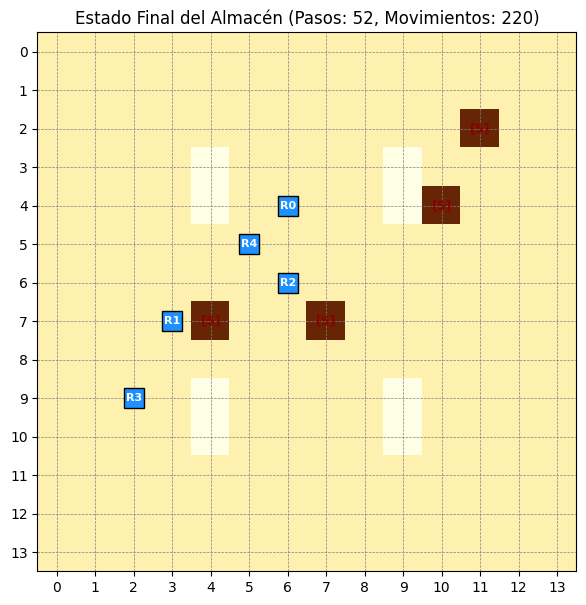

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))

# Dibujar cuadrícula
matriz = np.zeros((modelo.M, modelo.N))
for x, y in modelo.estantes:
    matriz[x, y] = -1  # Estantes
for x in range(modelo.M):
    for y in range(modelo.N):
        if modelo.cajas[x][y] > 0:
            matriz[x, y] = modelo.cajas[x][y]

ax.imshow(matriz.T, cmap="YlOrBr", vmin=-1, vmax=5, origin="upper")

# Dibujar posiciones de los robots
for r in modelo.robots:
    rx, ry = r.pos
    ax.plot(rx, ry, marker="s", markersize=14, color="dodgerblue", markeredgecolor="black")
    ax.text(rx, ry, f"R{r.numero}", color="white", ha="center", va="center", fontsize=8, weight="bold")

# Indicar pilas de 5 cajas
for px, py in modelo.pilas:
    altura = modelo.cajas[px][py]
    ax.text(px, py, f"[{altura}]", color="darkred", ha="center", va="center", fontsize=9, weight="bold")

ax.set_title(f"Estado Final del Almacén (Pasos: {tiempo_total}, Movimientos: {movs_totales})")
ax.set_xticks(range(modelo.M))
ax.set_yticks(range(modelo.N))
ax.grid(color="gray", linestyle="--", linewidth=0.5)
plt.show()


### 4. Análisis de Estrategia de Optimización

> **Pregunta del Reto:** *"Analiza si existe una estrategia que podría disminuir el tiempo dedicado, así como la cantidad de movimientos realizados. ¿Cómo sería? Descríbela."*

**Respuesta:**
Sí, es posible optimizar el tiempo y los movimientos mediante las siguientes mejoras cooperativas:

1. **Reserva Exclusiva de Cajas (Evitar Carreras):**
   Cuando un robot selecciona una caja suelta como objetivo, registra una reserva en el modelo. Los demás agentes descartan esa caja y eligen otra. Esto elimina los "conflictos de recolección" donde dos robots viajan por la misma caja y uno pierde el viaje.

2. **Heurística de Cierre de Pilas (Pack-First):**
   Al transportar una caja, los robots priorizan llevarla a la pila abierta que tenga más cajas (altura 4, luego 3, 2, 1). De esta forma se completan pilas de 5 rápidamente en lugar de dispersar cajas en muchas pilas a medio llenar.

3. **Planificación de Rutas con Evasión Local (BFS):**
   En lugar de movimientos aleatorios o líneas rectas que choquen con estantes o cajas, el agente calcula el camino más corto hacia una celda vecina libre, evitando callejones sin salida.
